# Análisis Exploratorio de Datos (EDA)

**Proyecto:** House Pricing — House Prices: Advanced Regression Techniques (Kaggle)

**Convención de nombre de notebook (Cookiecutter Data Science):**
`<paso>.<subpaso>-<iniciales>-<descripcion-corta>.ipynb`

- `1.0` = primer notebook del flujo de trabajo
- `ae` = iniciales del autor (Anderson Elias)
- `analisis-exploratorio` = descripción corta separada por guiones

---
Este notebook realiza una primera exploración de `train.csv` y `test.csv` ubicados en `data/raw/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Permite importar el paquete house_pricing (src) cuando se ejecuta desde notebooks/
sys.path.append(str(Path.cwd().parent))

from house_pricing.config import RAW_DATA_DIR

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

2026-11-09 18:41:52.839 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\Anderson Elias\OneDrive - Universidad Galileo\8vo. Trimestre\Product Development - B\house_pricing


## 1. Carga de datos

In [2]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f"train shape: {train.shape}")
print(f"test shape: {test.shape}")

train shape: (1460, 81)
test shape: (1459, 80)


In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Información general y tipos de datos

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


## 3. Valores faltantes

In [6]:
missing = train.isna().sum()
missing_pct = (missing / len(train) * 100).round(2)
missing_summary = (
    pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
missing_summary

,missing_count,missing_pct
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


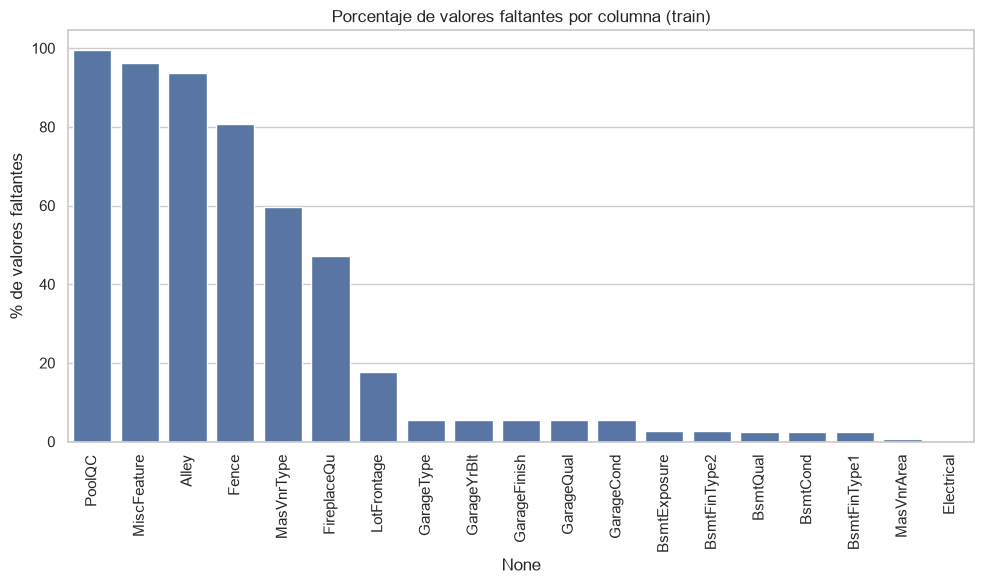

In [7]:
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_summary.index, y=missing_summary["missing_pct"])
plt.xticks(rotation=90)
plt.ylabel("% de valores faltantes")
plt.title("Porcentaje de valores faltantes por columna (train)")
plt.tight_layout()
plt.show()

## 4. Variable objetivo: `SalePrice`

In [8]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

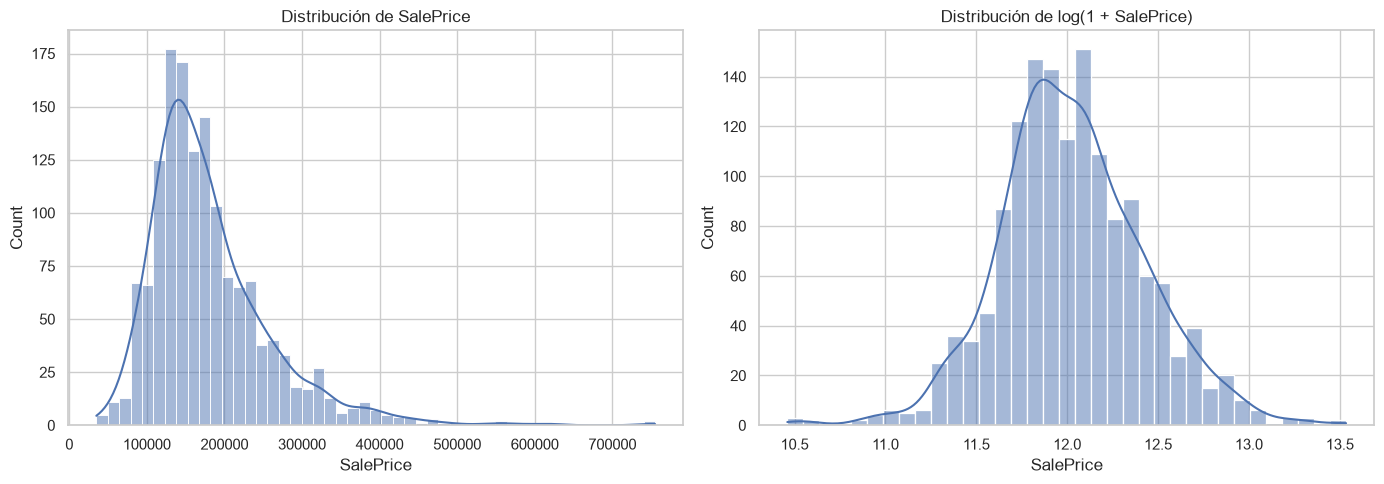

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Distribución de SalePrice")

sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("Distribución de log(1 + SalePrice)")

plt.tight_layout()
plt.show()

## 5. Correlaciones con la variable objetivo

In [10]:
numeric_cols = train.select_dtypes(include=[np.number]).columns
corr = train[numeric_cols].corr()["SalePrice"].sort_values(ascending=False)
corr.head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

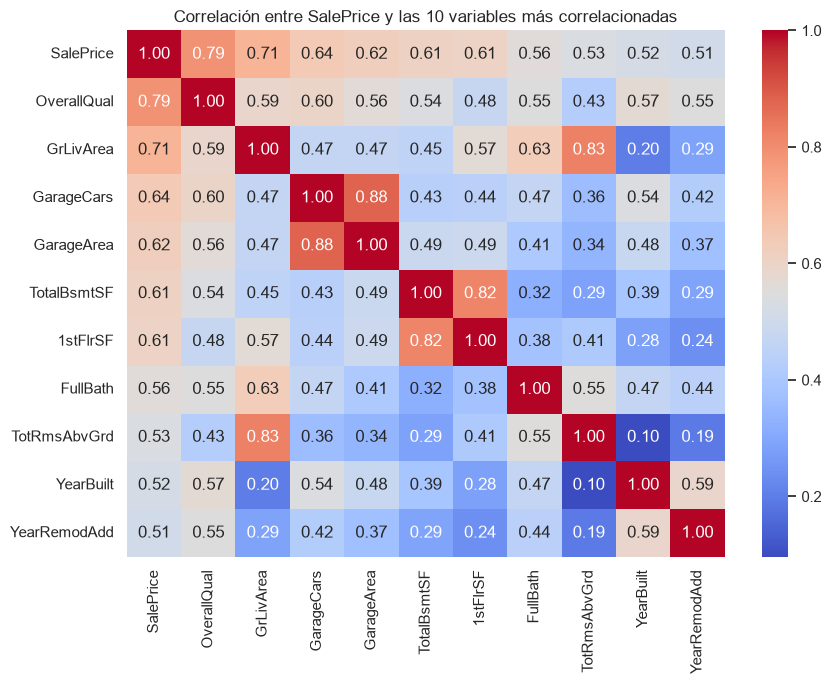

In [11]:
top_features = corr.index[1:11]

plt.figure(figsize=(9, 7))
sns.heatmap(
    train[["SalePrice", *top_features]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
)
plt.title("Correlación entre SalePrice y las 10 variables más correlacionadas")
plt.tight_layout()
plt.show()

## 6. Clasificación de variables numéricas: discretas vs continuas

Algunas de las variables numéricas en realidad son **discretas/ordinales** (tienen muy pocos valores únicos, por ejemplo `OverallQual` del 1 al 10), y eso provoca que sus scatter plots se vean como bandas verticales discontinuas en lugar de una nube continua de puntos. Esta celda separa las variables numéricas en dos grupos según su número de valores únicos (`nunique`): **discretas** (25 o menos valores únicos) y **continuas** (más de 25 valores únicos), y calcula la correlación de cada una con `SalePrice`.

In [12]:
numeric_features = train.select_dtypes(include=[np.number]).columns.drop(["Id", "SalePrice"])

# Umbral de valores únicos para considerar una variable como discreta
DISCRETE_THRESHOLD = 25
nunique = train[numeric_features].nunique()

discrete_features = nunique[nunique <= DISCRETE_THRESHOLD].index.tolist()
continuous_features = nunique[nunique > DISCRETE_THRESHOLD].index.tolist()

# Correlación de cada variable numérica con SalePrice, ordenada de mayor a menor
correlations = train[numeric_features].corrwith(train["SalePrice"]).sort_values(ascending=False)

corr_df = correlations.reset_index()
corr_df.columns = ["feature", "correlation_with_saleprice"]
corr_df["tipo"] = corr_df["feature"].apply(lambda f: "discreta" if f in discrete_features else "continua")

print(f"Variables discretas ({len(discrete_features)}): {discrete_features}")
print(f"Variables continuas ({len(continuous_features)}): {continuous_features}")

corr_df

Variables discretas (18): ['MSSubClass', 'OverallQual', 'OverallCond', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', '3SsnPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']
Variables continuas (18): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'ScreenPorch']


,feature,correlation_with_saleprice,tipo
0,OverallQual,0.790982,discreta
1,GrLivArea,0.708624,continua
2,GarageCars,0.640409,discreta
3,GarageArea,0.623431,continua
4,TotalBsmtSF,0.613581,continua
5,1stFlrSF,0.605852,continua
6,FullBath,0.560664,discreta
7,TotRmsAbvGrd,0.533723,discreta
8,YearBuilt,0.522897,continua
9,YearRemodAdd,0.507101,continua


## 7. Boxplots de variables discretas vs `SalePrice`

Para las variables **discretas** se usa un boxplot (eje x = variable, eje y = `SalePrice`) que resume cómo cambia la distribución del precio en cada categoría/valor. Se superpone un `stripplot` (con jitter) para mostrar los puntos individuales sobre cada caja, ya que el boxplot solo no deja ver la cantidad de datos ni su dispersión real.

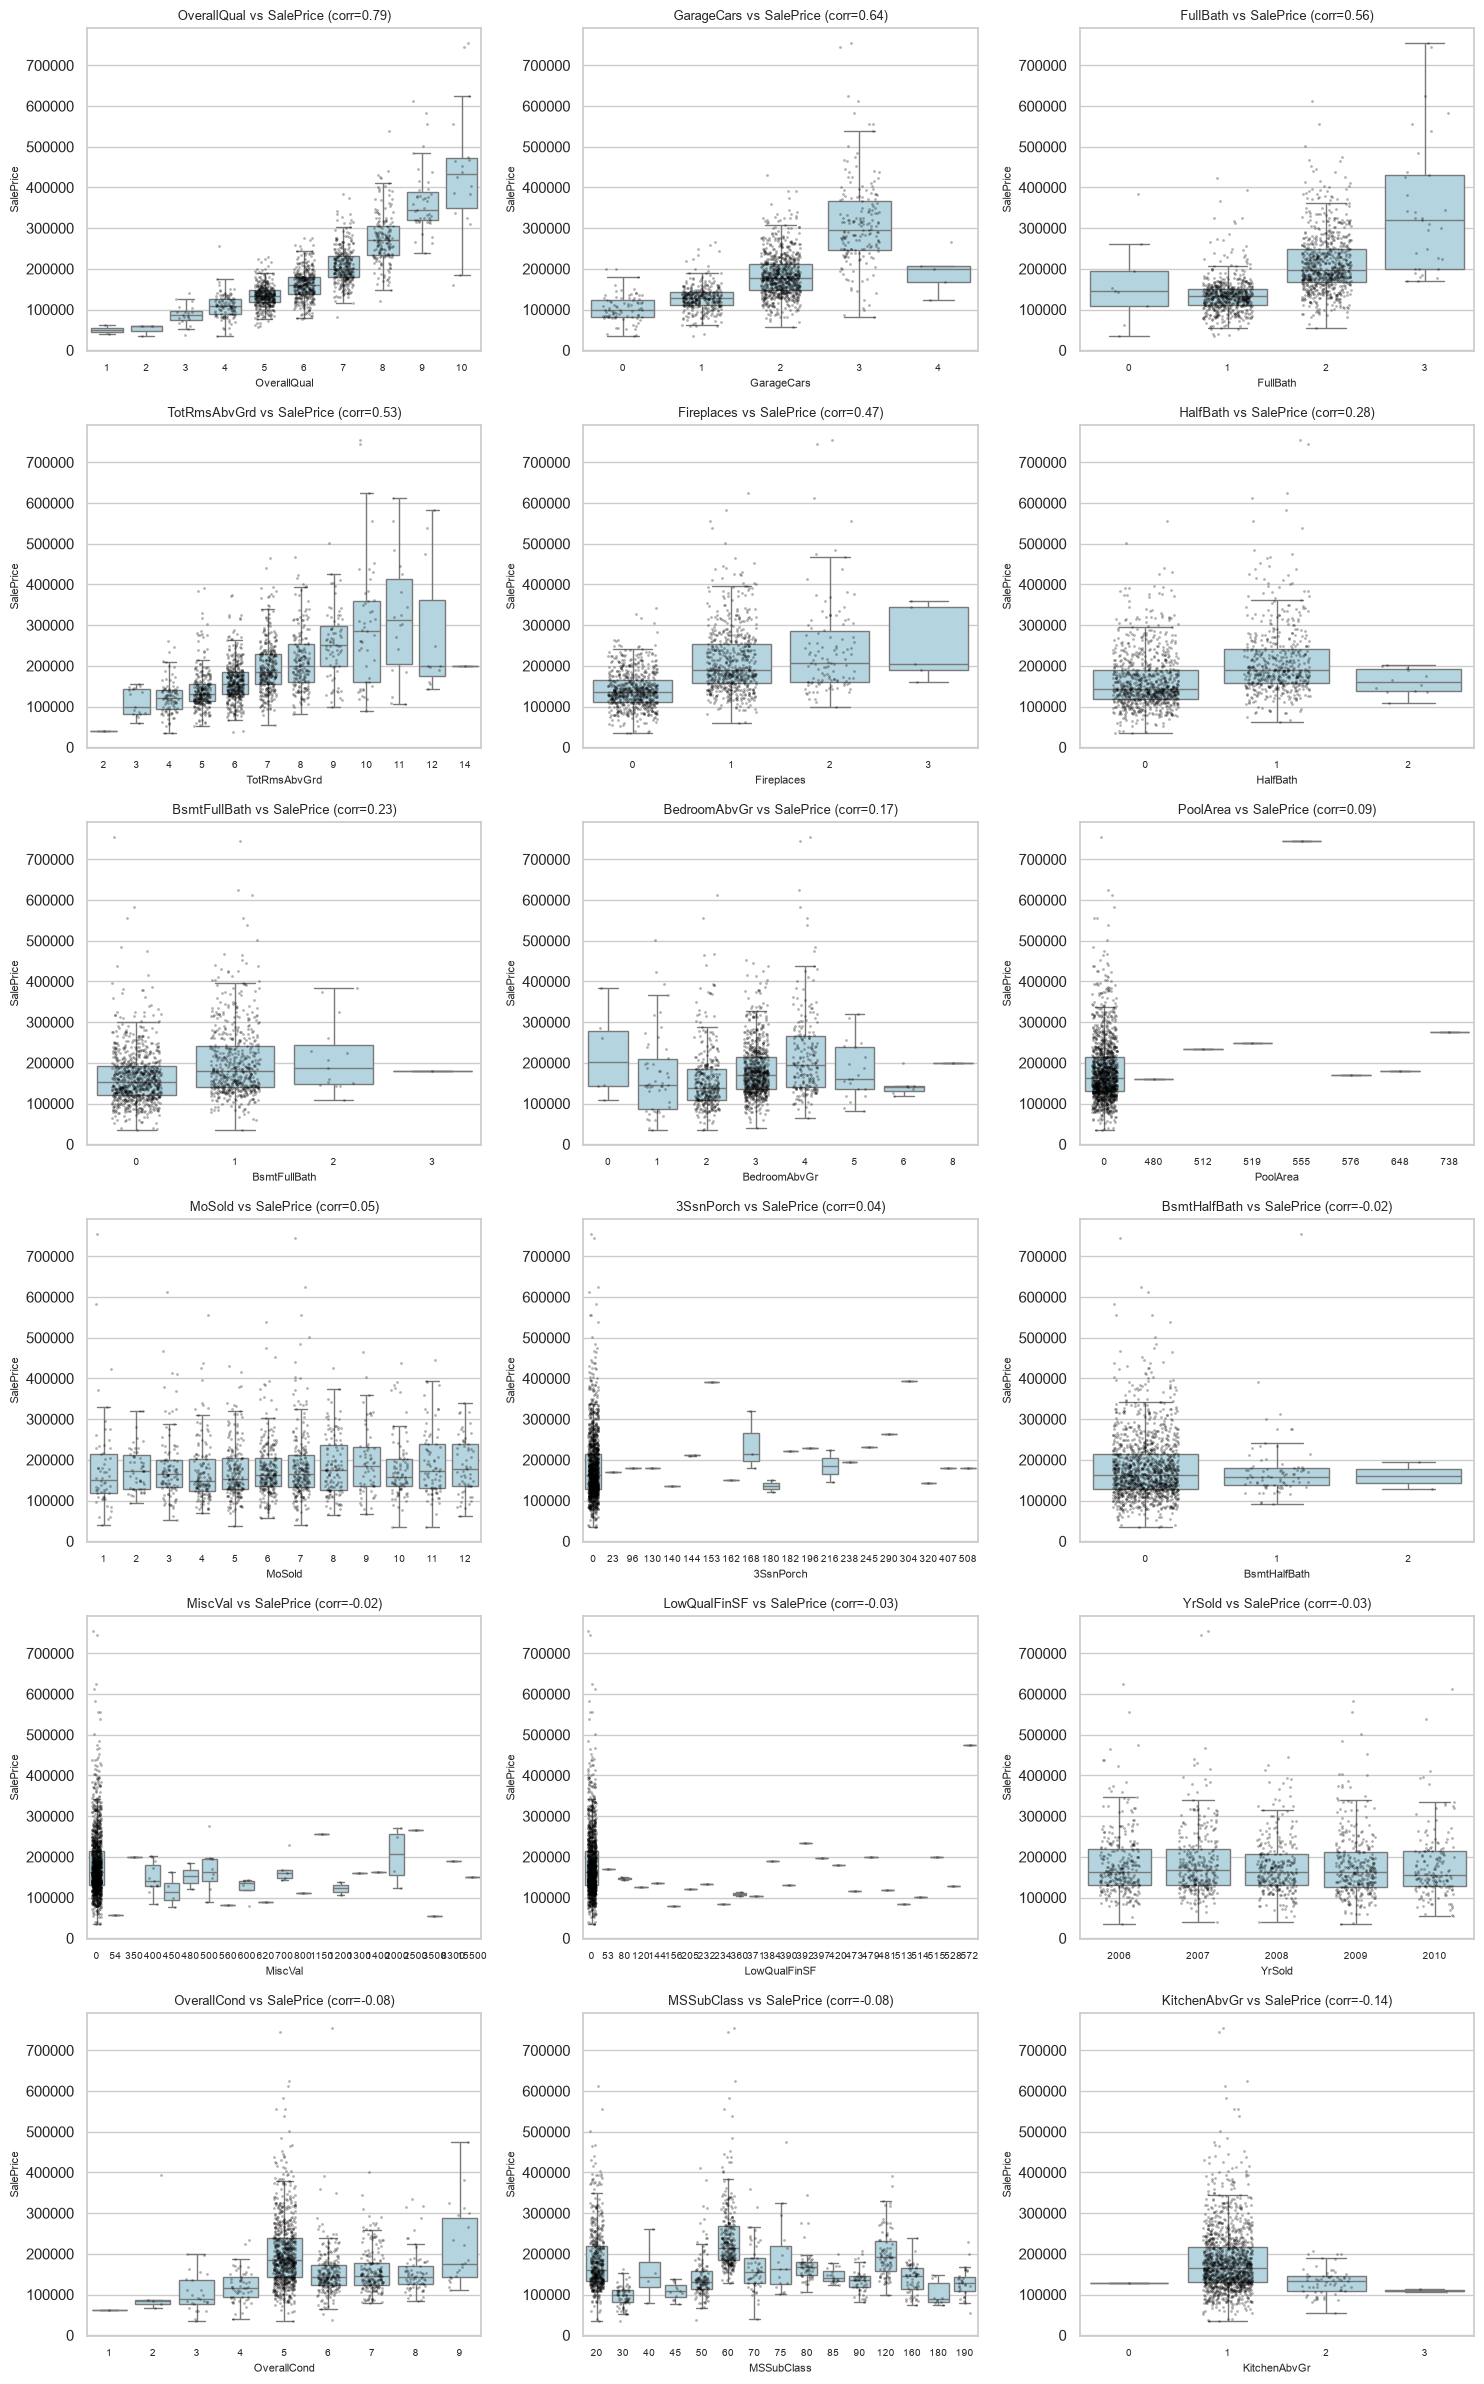

In [13]:
features_to_plot = [f for f in correlations.index if f in discrete_features]

n_cols = 3
n_features = len(features_to_plot)
n_rows = -(-n_features // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_plot):
    corr_value = correlations[feature]
    sns.boxplot(data=train, x=feature, y="SalePrice", ax=ax, color="lightblue", fliersize=0)
    sns.stripplot(
        data=train, x=feature, y="SalePrice", ax=ax,
        color="black", alpha=0.3, size=2, jitter=0.25,
    )
    ax.set_title(f"{feature} vs SalePrice (corr={corr_value:.2f})", fontsize=9)
    ax.set_xlabel(feature, fontsize=8)
    ax.set_ylabel("SalePrice", fontsize=8)
    ax.tick_params(axis="x", labelsize=7)

# Oculta los subplots sobrantes si el número de variables no llena la grilla
for ax in axes[n_features:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Boxplots de variables categóricas vs `SalePrice` (correlation ratio η)

Esta celda genera, en un ciclo, un boxplot por cada variable categórica (eje x = categoría, eje y = `SalePrice`) con los puntos individuales superpuestos (`stripplot`). Las categorías se ordenan por su mediana de `SalePrice` y los valores faltantes se tratan como la categoría `"NA"`, ya que en `data_description.txt` significan ausencia (ej. sin piscina, sin garage).

Como la correlación de Pearson no aplica a variables categóricas, se usa el **correlation ratio (η, eta)**:

$$\eta = \sqrt{\frac{\sum_k n_k(\bar{y}_k - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}}$$

Es la proporción de la varianza de `SalePrice` explicada por las diferencias entre las medias de cada categoría. Va de 0 (las categorías no separan el precio) a 1 (la categoría determina el precio por completo). El valor de η aparece en el título de cada gráfica y al final se muestra un DataFrame ordenado de mayor a menor.

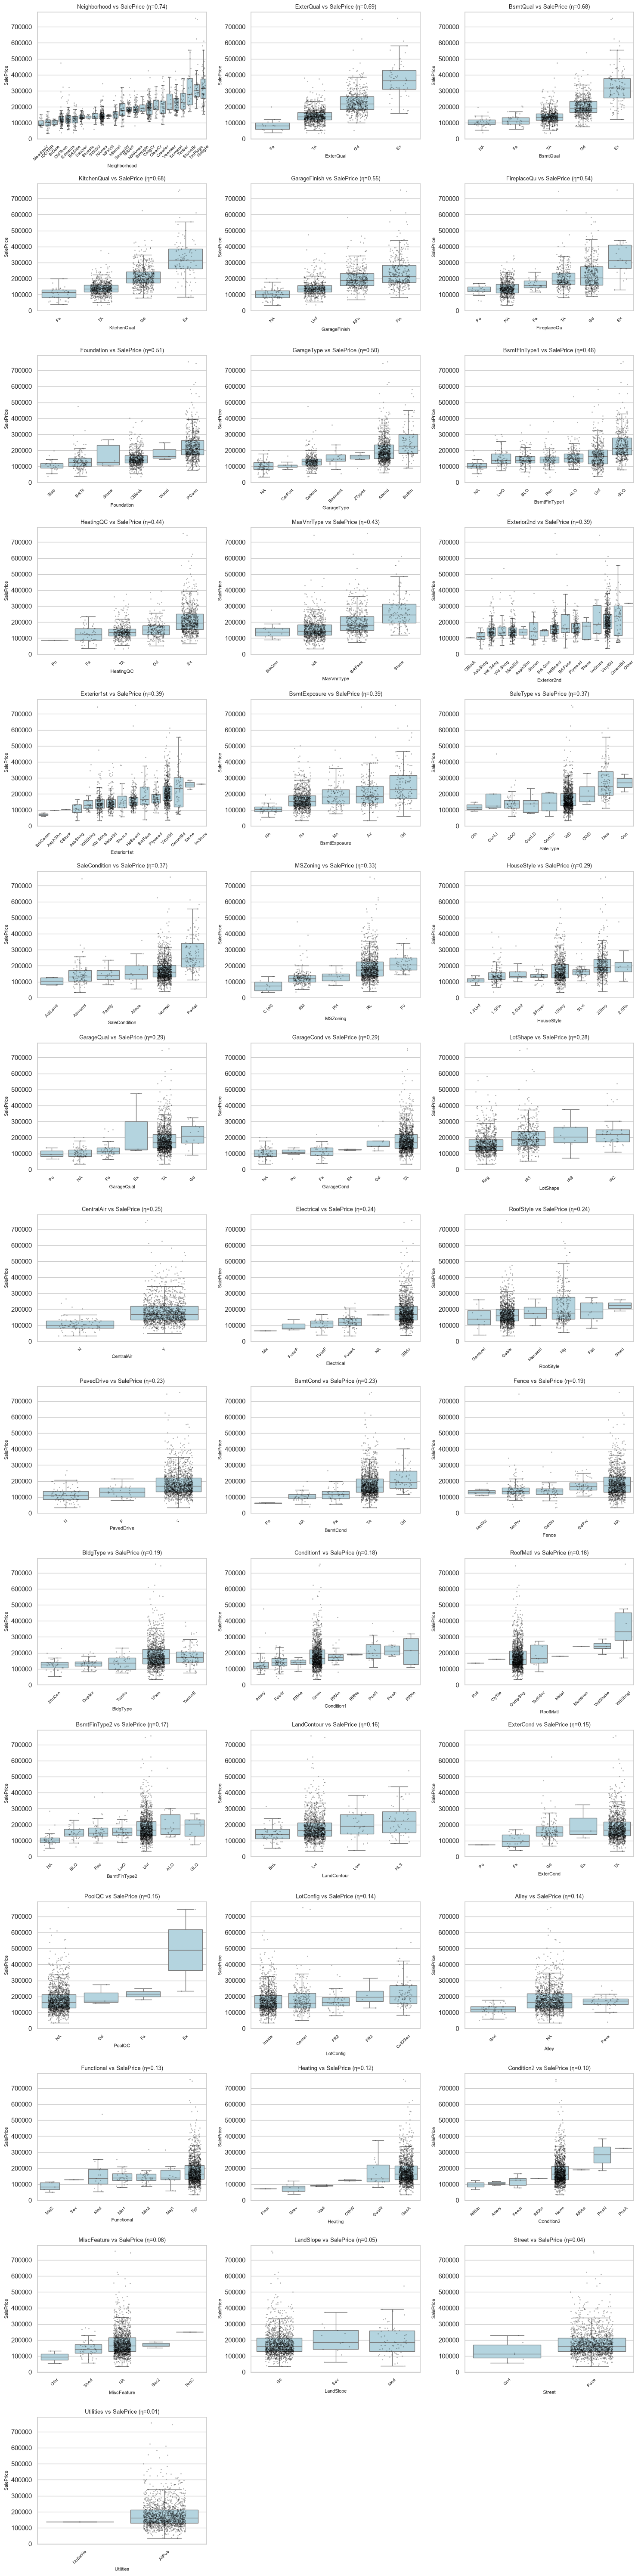

,feature,eta_with_saleprice,n_categorias
0,Neighborhood,0.738630,25
1,ExterQual,0.690933,4
2,BsmtQual,0.681905,5
3,KitchenQual,0.675721,4
4,GarageFinish,0.553059,4
5,FireplaceQu,0.542181,6
6,Foundation,0.506328,6
7,GarageType,0.499204,7
8,BsmtFinType1,0.459141,7
9,HeatingQC,0.442154,5


In [14]:
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    """Correlation ratio (eta) entre una variable categórica y una numérica."""
    grand_mean = values.mean()
    groups = values.groupby(categories)
    ss_between = (groups.count() * (groups.mean() - grand_mean) ** 2).sum()
    ss_total = ((values - grand_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total)


categorical_features = train.select_dtypes(exclude=[np.number]).columns.tolist()
train_cat = train[categorical_features].fillna("NA")

eta = pd.Series(
    {f: correlation_ratio(train_cat[f], train["SalePrice"]) for f in categorical_features}
).sort_values(ascending=False)

eta_df = eta.reset_index()
eta_df.columns = ["feature", "eta_with_saleprice"]
eta_df["n_categorias"] = eta_df["feature"].map(train_cat.nunique())

n_cols = 3
n_features = len(categorical_features)
n_rows = -(-n_features // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
axes = axes.flatten()

for ax, feature in zip(axes, eta.index):
    order = train["SalePrice"].groupby(train_cat[feature]).median().sort_values().index
    plot_data = pd.DataFrame({feature: train_cat[feature], "SalePrice": train["SalePrice"]})
    sns.boxplot(data=plot_data, x=feature, y="SalePrice", order=order, ax=ax, color="lightblue", fliersize=0)
    sns.stripplot(
        data=plot_data, x=feature, y="SalePrice", order=order, ax=ax,
        color="black", alpha=0.3, size=2, jitter=0.25,
    )
    ax.set_title(f"{feature} vs SalePrice (η={eta[feature]:.2f})", fontsize=9)
    ax.set_xlabel(feature, fontsize=8)
    ax.set_ylabel("SalePrice", fontsize=8)
    ax.tick_params(axis="x", labelsize=7, rotation=45)

# Oculta los subplots sobrantes si el número de variables no llena la grilla
for ax in axes[n_features:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

eta_df

## 9. Selección de features para el modelo

Esta celda selecciona las 10 mejores variables de cada grupo según las métricas calculadas: para continuas y discretas se usa el **valor absoluto** de la correlación de Pearson con `SalePrice` (una relación negativa fuerte también es informativa), y para categóricas el correlation ratio **η**. Los tres arreglos resultantes, unidos en `selected_features`, son las features con las que se construirá el modelo.

In [15]:
TOP_N = 10

top_continuous = correlations[continuous_features].abs().nlargest(TOP_N).index.tolist()
top_discrete = correlations[discrete_features].abs().nlargest(TOP_N).index.tolist()
top_categorical = eta.nlargest(TOP_N).index.tolist()

selected_features = top_continuous + top_discrete + top_categorical

print(f"top_continuous = {top_continuous}")
print(f"top_discrete = {top_discrete}")
print(f"top_categorical = {top_categorical}")
print()
print(f"Total de features seleccionadas: {len(selected_features)}")

top_continuous = ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
top_discrete = ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'PoolArea']
top_categorical = ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

Total de features seleccionadas: 30


## 10. Próximos pasos

- Analizar variables categóricas vs `SalePrice`.
- Decidir estrategia de imputación de valores faltantes.
- Detectar y tratar outliers (ej. `GrLivArea` vs `SalePrice`).
- Pasar la lógica de limpieza/feature engineering a `house_pricing/dataset.py` y `house_pricing/features.py`.